<a href="https://colab.research.google.com/github/Dara-Avyana/Tugas-ILP/blob/main/ILP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Simulator from https://github.com/harshitasingh4863/instruction-level-parallelism-simulator.git

from dataclasses import dataclass


@dataclass
class Instruction:
    name: str
    destination: str
    sources: list


# -------------------------------------------------
# Sample Instruction Set
# -------------------------------------------------

instructions = [
    Instruction("I1", "R1", ["R2", "R3"]),
    Instruction("I2", "R4", ["R5", "R6"]),
    Instruction("I3", "R7", ["R1", "R4"]),
    Instruction("I4", "R8", ["R9", "R10"]),
    Instruction("I5", "R11", ["R7", "R8"]),
    Instruction("I6", "R12", ["R13", "R14"]),
]


# -------------------------------------------------
# Function to check dependency
# -------------------------------------------------

def has_dependency(inst1, inst2):
    """
    Returns True if inst2 depends on inst1.
    """

    # RAW dependency:
    # inst2 reads a register written by inst1
    if inst1.destination in inst2.sources:
        return True

    return False


# -------------------------------------------------
# Sequential Execution
# -------------------------------------------------

def sequential_execution(instructions):
    print("\n" + "=" * 50)
    print("SEQUENTIAL EXECUTION")
    print("=" * 50)

    cycle = 0

    for instruction in instructions:
        cycle += 1

        print(
            f"Cycle {cycle}: Executing {instruction.name} "
            f"({instruction.destination} = "
            f"{' + '.join(instruction.sources)})"
        )

    print(f"\nTotal Sequential Cycles: {cycle}")

    return cycle


# -------------------------------------------------
# ILP / Parallel Execution
# -------------------------------------------------

def parallel_execution(instructions):
    print("\n" + "=" * 50)
    print("INSTRUCTION-LEVEL PARALLEL EXECUTION")
    print("=" * 50)

    completed = set()
    remaining = instructions.copy()

    cycle = 0

    while remaining:

        cycle += 1
        current_cycle = []

        for instruction in remaining:

            # Check whether all previous dependencies
            # have already been completed

            dependencies_satisfied = True

            for previous in instructions:

                if previous.name == instruction.name:
                    break

                if has_dependency(previous, instruction):
                    if previous.name not in completed:
                        dependencies_satisfied = False
                        break

            if dependencies_satisfied:
                current_cycle.append(instruction)

        # Execute all independent instructions
        # in the same cycle

        print(f"\nCycle {cycle}:")

        for instruction in current_cycle:
            print(
                f"  -> {instruction.name}: "
                f"{instruction.destination} = "
                f"{' + '.join(instruction.sources)}"
            )

        # Mark instructions as completed

        for instruction in current_cycle:
            completed.add(instruction.name)
            remaining.remove(instruction)

    print(f"\nTotal ILP Cycles: {cycle}")

    return cycle


# -------------------------------------------------
# Dependency Analysis
# -------------------------------------------------

def show_dependencies(instructions):

    print("\n" + "=" * 50)
    print("DEPENDENCY ANALYSIS")
    print("=" * 50)

    found = False

    for i in range(len(instructions)):

        for j in range(i + 1, len(instructions)):

            if has_dependency(instructions[i], instructions[j]):

                print(
                    f"{instructions[j].name} depends on "
                    f"{instructions[i].name} "
                    f"(Register: {instructions[i].destination})"
                )

                found = True

    if not found:
        print("No dependencies found.")


# -------------------------------------------------
# Main Program
# -------------------------------------------------

def main():

    print("\n")
    print("*" * 60)
    print("      INSTRUCTION-LEVEL PARALLELISM SIMULATOR")
    print("*" * 60)

    print("\nInstruction Set:")

    for instruction in instructions:
        print(
            f"{instruction.name}: "
            f"{instruction.destination} = "
            f"{' + '.join(instruction.sources)}"
        )

    # Show dependencies

    show_dependencies(instructions)

    # Sequential execution

    sequential_cycles = sequential_execution(instructions)

    # Parallel execution

    parallel_cycles = parallel_execution(instructions)

    # Calculate speedup

    speedup = sequential_cycles / parallel_cycles

    efficiency = speedup / len(instructions) * 100

    print("\n" + "=" * 50)
    print("PERFORMANCE COMPARISON")
    print("=" * 50)

    print(f"Sequential Cycles : {sequential_cycles}")
    print(f"ILP Cycles        : {parallel_cycles}")
    print(f"Speedup            : {speedup:.2f}x")
    print(f"ILP Efficiency     : {efficiency:.2f}%")

    print("\nConclusion:")
    print(
        "ILP reduces execution cycles by allowing "
        "independent instructions to execute in parallel."
    )


# -------------------------------------------------
# Run Program
# -------------------------------------------------

if __name__ == "__main__":
    main()




************************************************************
      INSTRUCTION-LEVEL PARALLELISM SIMULATOR
************************************************************

Instruction Set:
I1: R1 = R2 + R3
I2: R4 = R5 + R6
I3: R7 = R1 + R4
I4: R8 = R9 + R10
I5: R11 = R7 + R8
I6: R12 = R13 + R14

DEPENDENCY ANALYSIS
I3 depends on I1 (Register: R1)
I3 depends on I2 (Register: R4)
I5 depends on I3 (Register: R7)
I5 depends on I4 (Register: R8)

SEQUENTIAL EXECUTION
Cycle 1: Executing I1 (R1 = R2 + R3)
Cycle 2: Executing I2 (R4 = R5 + R6)
Cycle 3: Executing I3 (R7 = R1 + R4)
Cycle 4: Executing I4 (R8 = R9 + R10)
Cycle 5: Executing I5 (R11 = R7 + R8)
Cycle 6: Executing I6 (R12 = R13 + R14)

Total Sequential Cycles: 6

INSTRUCTION-LEVEL PARALLEL EXECUTION

Cycle 1:
  -> I1: R1 = R2 + R3
  -> I2: R4 = R5 + R6
  -> I4: R8 = R9 + R10
  -> I6: R12 = R13 + R14

Cycle 2:
  -> I3: R7 = R1 + R4

Cycle 3:
  -> I5: R11 = R7 + R8

Total ILP Cycles: 3

PERFORMANCE COMPARISON
Sequential Cycles : 6
ILP Cyc

In [17]:
# =================================================
# BAGIAN 1: IMPLEMENTASI RAW (Read After Write)
# =================================================
import networkx as nx
import matplotlib.pyplot as plt

def check_raw(inst1, inst2):
    """Mengecek RAW (True Data Dependence): inst2 membaca register yang ditulis inst1"""
    if inst1.destination in inst2.sources:
        return inst1.destination
    return None

# Skenario Instruksi khusus uji RAW (Mengacu pada Slide 3 bagian a)
raw_instructions = [
    Instruction("I1", "R1", ["R2", "R3"]),  # Menulis R1
    Instruction("I2", "R4", ["R1", "R5"]),  # RAW pada R1 dari I1
    Instruction("I3", "R6", ["R4", "R7"]),  # RAW pada R4 dari I2
    Instruction("I4", "R8", ["R9", "R10"]), # Independen (jalan di Cycle 1)
    Instruction("I5", "R11", ["R6", "R8"]), # RAW pada R6 (dari I3) dan R8 (dari I4)
]

print("Dataset Instruksi RAW berhasil dibuat:")
for inst in raw_instructions:
    print(f"  {inst.name}: {inst.destination} = {' + '.join(inst.sources)}")

Dataset Instruksi RAW berhasil dibuat:
  I1: R1 = R2 + R3
  I2: R4 = R1 + R5
  I3: R6 = R4 + R7
  I4: R8 = R9 + R10
  I5: R11 = R6 + R8


In [18]:
# Menjalankan simulasi Sequential vs ILP untuk skenario RAW
seq_raw = sequential_execution(raw_instructions)
ilp_raw = parallel_execution(raw_instructions)

speedup_raw = seq_raw / ilp_raw
efficiency_raw = (speedup_raw / len(raw_instructions)) * 100

print(f"\nRingkasan Performa Skenario RAW:")
print(f"Speedup: {speedup_raw:.2f}x | ILP Efficiency: {efficiency_raw:.2f}%")


SEQUENTIAL EXECUTION
Cycle 1: Executing I1 (R1 = R2 + R3)
Cycle 2: Executing I2 (R4 = R1 + R5)
Cycle 3: Executing I3 (R6 = R4 + R7)
Cycle 4: Executing I4 (R8 = R9 + R10)
Cycle 5: Executing I5 (R11 = R6 + R8)

Total Sequential Cycles: 5

INSTRUCTION-LEVEL PARALLEL EXECUTION

Cycle 1:
  -> I1: R1 = R2 + R3
  -> I4: R8 = R9 + R10

Cycle 2:
  -> I2: R4 = R1 + R5

Cycle 3:
  -> I3: R6 = R4 + R7

Cycle 4:
  -> I5: R11 = R6 + R8

Total ILP Cycles: 4

Ringkasan Performa Skenario RAW:
Speedup: 1.25x | ILP Efficiency: 25.00%


DEPENDENCY ANALYSIS - RAW (True Data Dependence)
[RAW] I2 depends on I1 (Register: R1)
[RAW] I3 depends on I2 (Register: R4)
[RAW] I5 depends on I3 (Register: R6)
[RAW] I5 depends on I4 (Register: R8)


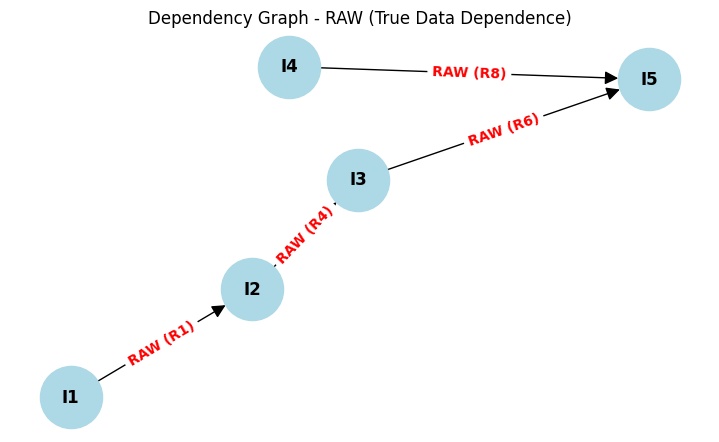

In [19]:
# Analisis Ketergantungan & Visualisasi Dependency Graph RAW
def run_raw_analysis(inst_list):
    print("=" * 50)
    print("DEPENDENCY ANALYSIS - RAW (True Data Dependence)")
    print("=" * 50)
    G = nx.DiGraph()
    for inst in inst_list:
        G.add_node(inst.name)

    for i in range(len(inst_list)):
        for j in range(i + 1, len(inst_list)):
            reg = check_raw(inst_list[i], inst_list[j])
            if reg:
                print(f"[RAW] {inst_list[j].name} depends on {inst_list[i].name} (Register: {reg})")
                G.add_edge(inst_list[i].name, inst_list[j].name, label=f"RAW ({reg})")

    plt.figure(figsize=(7, 4))
    pos = nx.spring_layout(G, seed=42)
    nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=2000, font_weight='bold', arrows=True, arrowsize=20)
    edge_labels = nx.get_edge_attributes(G, 'label')
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color='red', font_weight='bold')
    plt.title("Dependency Graph - RAW (True Data Dependence)")
    plt.show()

run_raw_analysis(raw_instructions)

## WAR — Write After Read (Anti-dependence)
Tambahan ini menggunakan simulator dasar tanpa mengubah fungsi atau skenario RAW.
Panah WAR menunjukkan urutan akses register, bukan aliran hasil perhitungan.
Penjadwal baru memeriksa RAW + WAR. WAW belum dimodelkan.
Satu instruksi memerlukan satu siklus; dependensi menunggu siklus berikutnya. Angka ini bukan pengukuran CPU nyata.
Kode direkonstruksi dari percakapan sebelumnya; berkas WAR_tambahan.py lama tidak tersedia pada sesi integrasi.

In [ ]:
# BAGIAN 2: IMPLEMENTASI WAR (Write After Read)
# Jalankan sel simulator dasar terlebih dahulu.
def check_war(inst1, inst2):
    """inst1 lebih awal; inst2 menulis register yang dibaca inst1."""
    if inst2.destination in inst1.sources:
        return inst2.destination
    return None


def war_schedule(inst_list):
    """Jadwal RAW + WAR; satu siklus/instruksi, unit eksekusi tak dibatasi.

    Pendahulu harus selesai pada siklus sebelumnya. Ini model konservatif
    tingkat instruksi, bukan simulasi tahap baca/tulis pipeline CPU.
    WAW belum dimodelkan; gunakan skenario tanpa tujuan tulis berulang.
    """
    completed = set()
    schedule = []
    while len(completed) < len(inst_list):
        ready = [
            i for i, inst in enumerate(inst_list)
            if i not in completed and all(
                j in completed
                for j, previous in enumerate(inst_list[:i])
                if has_dependency(previous, inst)
                or check_war(previous, inst) is not None
            )
        ]
        schedule.append([inst_list[i] for i in ready])
        completed.update(ready)
    return schedule


def parallel_execution_war(inst_list):
    """Menjalankan penjadwal RAW + WAR tanpa mengganti parallel_execution."""
    schedule = war_schedule(inst_list)
    print("INSTRUCTION-LEVEL PARALLEL EXECUTION (RAW + WAR)")
    for cycle, batch in enumerate(schedule, start=1):
        print(f"Cycle {cycle}: " + ", ".join(inst.name for inst in batch))
    print(f"Total ILP Cycles: {len(schedule)}")
    return len(schedule)


def run_war_analysis(inst_list):
    """Grafik hanya menampilkan WAR; penjadwal juga memeriksa RAW."""
    import networkx as nx
    import matplotlib.pyplot as plt

    graph = nx.DiGraph()
    # Indeks menjaga identitas instruksi meskipun namanya sama.
    graph.add_nodes_from(range(len(inst_list)))
    for i, earlier in enumerate(inst_list):
        for j in range(i + 1, len(inst_list)):
            reg = check_war(earlier, inst_list[j])
            if reg is not None:
                print(f"[WAR] {earlier.name} membaca {reg} sebelum "
                      f"{inst_list[j].name} menulis {reg}")
                graph.add_edge(i, j, label=f"WAR ({reg})")
    plt.figure(figsize=(7, 4))
    pos = nx.spring_layout(graph, seed=42)
    nx.draw(graph, pos, labels={i: inst.name for i, inst in enumerate(inst_list)},
            with_labels=True, node_color="lightgreen", node_size=2000,
            font_weight="bold", arrows=True, arrowsize=20)
    nx.draw_networkx_edge_labels(graph, pos,
                                edge_labels=nx.get_edge_attributes(graph, "label"))
    plt.title("Dependency Graph - WAR (Anti-dependence)")
    plt.show()
    return graph


In [ ]:
# Contoh pasangan WAR yang dibahas dalam tugas.
war_instructions = [
    Instruction("I1", "R1", ["R2", "R3"]),
    Instruction("I2", "R2", ["R4", "R5"]),
]
seq_war = sequential_execution(war_instructions)
ilp_war = parallel_execution_war(war_instructions)
print(f"Speedup WAR: {seq_war / ilp_war:.2f}x")
war_graph = run_war_analysis(war_instructions)

# Pengembangan untuk pengujian, bukan kutipan slide.
# WAR: I1 -> I2 (R2), I2 -> I3 (R4); RAW: I4 -> I5 (R8).
war_extended_instructions = [
    Instruction("I1", "R1", ["R2", "R3"]),
    Instruction("I2", "R2", ["R4", "R5"]),
    Instruction("I3", "R4", ["R6", "R7"]),
    Instruction("I4", "R8", ["R9", "R10"]),
    Instruction("I5", "R11", ["R8", "R12"]),
]
seq_war_extended = sequential_execution(war_extended_instructions)
ilp_war_extended = parallel_execution_war(war_extended_instructions)
print(f"Speedup WAR pengembangan: {seq_war_extended / ilp_war_extended:.2f}x")


In [ ]:
# =================================================
# BAGIAN 3: IMPLEMENTASI WAW & GABUNGAN PENUH
# =================================================
import networkx as nx
import matplotlib.pyplot as plt

def check_waw(inst1, inst2):
    if inst1.destination == inst2.destination:
        return inst2.destination
    return None

def get_dependencies(earlier, later):
    deps = []
    if has_dependency(earlier, later):
        deps.append(('RAW', earlier.destination))
    reg = check_war(earlier, later)
    if reg is not None:
        deps.append(('WAR', reg))
    reg = check_waw(earlier, later)
    if reg is not None:
        deps.append(('WAW', reg))
    return deps

def full_schedule(inst_list):
    completed = set()
    schedule = []
    while len(completed) < len(inst_list):
        ready = [
            i for i, inst in enumerate(inst_list)
            if i not in completed and all(
                j in completed
                for j, previous in enumerate(inst_list[:i])
                if get_dependencies(previous, inst)
            )
        ]
        schedule.append([inst_list[i] for i in ready])
        completed.update(ready)
    return schedule

def parallel_execution_waw(inst_list):
    schedule = full_schedule(inst_list)
    print('INSTRUCTION-LEVEL PARALLEL EXECUTION (RAW + WAR + WAW)')
    for cycle, batch in enumerate(schedule, start=1):
        print(f'Cycle {cycle}: ' + ', '.join(inst.name for inst in batch))
    print(f'Total ILP Cycles: {len(schedule)}')
    return len(schedule)

def run_waw_analysis(inst_list):
    print('=' * 50)
    print('DEPENDENCY ANALYSIS - WAW (Output Dependence)')
    print('=' * 50)
    graph = nx.DiGraph()
    graph.add_nodes_from(range(len(inst_list)))
    for i, earlier in enumerate(inst_list):
        for j in range(i + 1, len(inst_list)):
            reg = check_waw(earlier, inst_list[j])
            if reg is not None:
                print(f'[WAW] {earlier.name} dan {inst_list[j].name} sama-sama menulis {reg}')
                graph.add_edge(i, j, label=f'WAW ({reg})')
    plt.figure(figsize=(7, 4))
    pos = nx.spring_layout(graph, seed=42)
    nx.draw(graph, pos, labels={i: inst.name for i, inst in enumerate(inst_list)},
            with_labels=True, node_color='moccasin', node_size=2000,
            font_weight='bold', arrows=True, arrowsize=20)
    nx.draw_networkx_edge_labels(graph, pos, edge_labels=nx.get_edge_attributes(graph, 'label'))
    plt.title('Dependency Graph - WAW (Output Dependence)')
    plt.show()
    return graph

# Skenario Uji WAW (Slide 3 c)
waw_instructions = [
    Instruction('I1', 'R1', ['R2', 'R3']),
    Instruction('I2', 'R4', ['R1', 'R5']),
    Instruction('I3', 'R1', ['R6', 'R7']),
    Instruction('I4', 'R8', ['R9', 'R10']),
    Instruction('I5', 'R8', ['R11', 'R12']),
]

run_waw_analysis(waw_instructions)
seq_waw = sequential_execution(waw_instructions)
ilp_waw = parallel_execution_waw(waw_instructions)
print(f'Speedup WAW: {seq_waw / ilp_waw:.2f}x')
